# Aula 03 - Explicabilidade Local com LIME e a Sensibilidade no Limiar de Decisão

**Disciplina:** Inteligência Artificial Explicável (XAI) & Otimização de Modelos  
**Autor / Pesquisador:** Eduardo Lázaro Roesler de Oliveira  
**Instituição:** UNESP — Universidade Estadual Paulista "Júlio de Mesquita Filho" (Mestrado)  

> **Escopo:** Os dados sao sinteticos e os exemplos medicos sao ilustrativos; os resultados nao sao recomendacoes clinicas.

> 🔙 **De onde viemos:** Na Aula 02, calculamos a importancia media das variaveis sinteticas pelo SHAP. O ranking descreve o modelo e o split, sem identificar biomarcadores reais. O LIME complementa essa analise com uma aproximacao local.
> 🎯 **Objetivo Principal da Aula:** Dominar os fundamentos do **LIME (Local Interpretable Model-agnostic Explanations)**, localizar uma observacao sintetica de teste com probabilidade proxima de $0.50$, auditar localmente sua predicao e visualizar regras aproximadas. O LIME nao e ranking global nem seletor de atributos.
> 🚀 **Para onde vamos:** Na Aula 04, o estudo de ablação comparará SHAP com três famílias de baseline: filter (mutual information), wrapper (RFE) e embedded (regressão logística L1).

## Organização Tática da Aula

| Módulo | Atividade | Foco Pedagógico |
| :--- | :--- | :--- |
| **Módulo 1** | **Fundamentação Teórica & Por que Explicar Casos Locais?** | A necessidade de transparência individual, a fragilidade de decisões limítrofes e a hipótese de linearidade local. |
| **Módulo 2** | **O Mecanismo por Dentro & Matemática da Perturbação Local** | A formulação do modelo substituto (*surrogate*), o kernel de ponderação por distância e o comparativo SHAP vs. LIME. |
| **Módulo 3** | **Prática Guiada no Google Colab** | 6 blocos de código em Python minuciosamente comentados linha por linha, com gráficos bicolores e dúvidas comuns. |
| **Módulo 4** | **Prática Orientada & Experimentação Fácil** | Experimentação comparando a explicação de um paciente limítrofe ($P \approx 0.50$) contra um paciente de certeza absoluta ($P > 0.95$). |
| **Módulo 5** | **Checklist de Autonomia & Bibliografia** | Autoavaliação do estudante e referências seminais. |

## Módulo 1: Fundamentação Teórica & Por que Explicar Casos Locais?

### 1.1 A Fronteira Crítica de Decisão ($P \approx 0.50$)
Imagine que dois pacientes chegam à emergência com sintomas parecidos:
- **Paciente A:** O modelo prediz **99.2% de probabilidade de patologia**. Aqui, os exames estão tão alterados que até um estudante iniciante acertaria o diagnóstico.
- **Paciente B:** O modelo prediz **50.4% de probabilidade de patologia**. O algoritmo classificará o paciente como "Doente" apenas por uma fração de 0.4%! 

É exatamente no limiar de decisão de 50% que ocorrem os maiores riscos de erro médico e onde a Inteligência Artificial precisa ser auditada com rigor máximo. Se o modelo atribuiu 50.4% por causa de um exame vital ou por causa de um ruído térmico aleatório, isso define se o paciente receberá um tratamento invasivo ou irá para casa!

```mermaid
graph LR
    A["Paciente #127<br/>No Limiar (P = 50.4%)"] --> B["🌪️ Perturbação Local (LIME)<br/>Cria 5.000 variações sintéticas ao redor do paciente"]
    B --> C["⚖️ Ponderação por Distância<br/>Pontos mais próximos recebem mais peso"]
    C --> D["📐 Ajuste de Modelo Linear Simples<br/>(Regressão com Lasso)"]
    D --> E["📊 Regras e Pesos Locais Explicados<br/>Biomarcador_1 > 1.2 (+14%)<br/>Biomarcador_3 <= 0.8 (-10%)"]
```

> ⚔️ **Analogia Geek — O Horizonte Plano e a Terra Redonda:**
> Em escala planetária, a Terra é redonda e curva (não-linear e complexa como um Random Forest ou Rede Neural profunda). Mas quando você vai construir uma casa ou jogar futebol no campinho do seu bairro, você não precisa calcular a curvatura da Terra: na sua vizinhança imediata de 50 metros, o chão se comporta **perfeitamente como um plano reto**!  
> O **LIME** aplica exatamente esse princípio: ele não tenta entender o modelo complexo inteiro de uma vez; ele dá um zoom milimétrico em torno de um único paciente e ajusta uma "linha reta" (regressão linear simples) que qualquer ser humano consegue entender!

> 💡 **Curiosidade Histórica — O Famoso Caso do Lobo vs. Husky (KDD 2016):**
> No artigo de lançamento do LIME, o pesquisador brasileiro **Marco Tulio Ribeiro** treinou uma rede neural de visão computacional de altíssima precisão para diferenciar fotos de Lobos e cães Husky. Ao aplicar o LIME para entender por que o modelo classificava uma imagem como "Lobo", eles descobriram o absurdo: a rede neural estava olhando **para a neve no chão** e não para o animal! Sempre que havia neve no fundo, ela cravava "Lobo". Sem a explicabilidade local, um modelo completamente defeituoso teria sido colocado em produção!

> 💡 **Em 1 Frase:** O LIME gera milhares de pequenas variações ao redor de uma pessoa específica para descobrir quais variáveis, se ligeiramente alteradas, fariam o modelo mudar de ideia sobre aquela pessoa.

## Módulo 2: O Mecanismo por Dentro & Regras Práticas

### 2.1 A Formulação Matemática do LIME

O objetivo do LIME é encontrar uma explicação $g$ pertencente a uma família de modelos simples e interpretáveis $G$ (ex: regressões lineares ou árvores rasas), minimizando a seguinte função de perda:

$$\xi(x) = \arg\min_{g \in G} \mathcal{L}(f, g, \pi_x) + \Omega(g)$$

Onde:
1. $f(x)$: É a previsão do modelo caixa-preta complexo original.
2. $g(z)$: É o modelo linear interpretável simples que estamos ajustando localmente.
3. $\mathcal{L}(f, g, \pi_x)$: É o erro de aproximação entre o modelo complexo e o modelo simples na vizinhança do ponto $x$.
4. $\pi_x(z) = \exp\left(-\frac{D(x, z)^2}{\sigma^2}\right)$: É a função de proximidade (Kernel Exponencial). Amostras sintéticas muito parecidas com o paciente recebem peso próximo de $1$; amostras distantes recebem peso próximo de $0$.
5. $\Omega(g)$: É uma penalidade de complexidade (ex: limitar a explicação a no máximo 5 ou 10 regras para não sobrecarregar o médico).

### 2.2 Comparativo Tático: SHAP vs. LIME

| Dimensão | SHAP (Shapley Additive exPlanations) | LIME (Local Interpretable Model-agnostic Explanations) |
| :--- | :--- | :--- |
| **Origem Teórica** | Teoria dos Jogos Cooperativos (Axiomas de Shapley, 1953). | Amostragem por Perturbação Estocástica e Modelos Substitutos Locais (2016). |
| **Agnosticismo** | Versões específicas para árvores (`TreeSHAP`) são dependentes da arquitetura, mas ultrarrápidas. | **100% Agnóstico:** Funciona com qualquer modelo que receba entrada e cuspa probabilidade. |
| **Formato das Regras** | Valores contínuos brutos atribuídos a cada coluna. | Regras condicionais em faixas de valores (ex: $2.5 < \text{glicemia} \le 4.1$). |
| **Determinismo** | Determinístico (mesmo dado produz exatamente os mesmos valores). | Levemente estocástico (usa perturbação pseudoaleatória de vizinhança). |
| **Melhor Aplicação** | Ranqueamento global de variáveis e seleção de atributos. | Auditoria forense de casos limítrofes individuais e explicabilidade em tela para usuários. |

> 💡 **Em 1 Frase:** Use o SHAP para entender a inteligência global do modelo e selecionar variáveis; use o LIME para justificar um diagnóstico polêmico para um paciente ou órgão regulador.

## Módulo 3: Prática Guiada no Google Colab

Abra o seu Notebook no [Google Colab](https://colab.research.google.com) e acompanhe a execução dos blocos a seguir.

> **Roteiro de estudo:** Recuperaremos o nosso conjunto de dados clínicos e o modelo treinado. Criaremos o objeto explicador do LIME, usaremos uma busca matemática com `np.argmin` para encontrar o paciente mais incerto do teste ($P \approx 0.50$) e plotaremos um gráfico de barras bicolores intuitivo.

### Bloco 3.1 — Reutilização do Dataset e do Modelo Baseline

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que o LIME precisa do método `predict_proba` do modelo?**  
> Porque o LIME precisa saber a curvatura contínua de incerteza do modelo na vizinhança (ex: 48%, 51%, 53%) para ajustar uma regressão linear suave, em vez de apenas rótulos rígidos de 0 e 1.

In [1]:
# 1. Importamos as bibliotecas fundamentais de manipulacao tabular e visualizacao
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 2. Importamos o modulo tabular da biblioteca LIME especializada em dados tabulares
from lime import lime_tabular

# 3. Importamos os geradores sinteticos e classificadores do scikit-learn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 4. Sintetizamos novamente a coorte clinica com 40 atributos
def gerar_dataset_sintetico_saude(n_samples=2000, n_features=40, n_informative=10, n_redundant=10, random_state=42):
    X_raw, y = make_classification(
        n_samples=n_samples, n_features=n_features, n_informative=n_informative,
        n_redundant=n_redundant, n_repeated=0, n_classes=2, weights=[0.6, 0.4],
        flip_y=0.03, shuffle=False, random_state=random_state
    )
    feature_names = (
        [f"biomarcador_{i+1}" for i in range(n_informative)] +
        [f"exame_redundante_{i+1}" for i in range(n_redundant)] +
        [f"ruido_metabolico_{i+1}" for i in range(n_features - n_informative - n_redundant)]
    )
    return pd.DataFrame(X_raw, columns=feature_names), y

# 5. Instanciamos os dados e realizamos o particionamento estratificado
X, y = gerar_dataset_sintetico_saude()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 6. Treinamos o Random Forest de referencia com todas as variaveis
modelo_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1)
modelo_baseline.fit(X_train, y_train)

# 7. Computamos as probabilidades de patologia previstas para todo o conjunto de teste
y_proba_teste = modelo_baseline.predict_proba(X_test)[:, 1]

# 8. Confirmamos o ajuste do modelo no console
print(f"[OK] Modelo ajustado! Avaliando previsões contínuas para {len(y_proba_teste)} pacientes de teste.")

[OK] Modelo ajustado! Avaliando previsões contínuas para 500 pacientes de teste.


---

### Bloco 3.2 — Instanciando o `LimeTabularExplainer`

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que passamos `np.array(X_train)` para o `LimeTabularExplainer`?**  
> O LIME precisa calcular as médias e desvios padrões empíricos do conjunto de treinamento para gerar perturbações gaussianas sintéticas realistas ao redor do paciente.

In [2]:
# 1. Definimos a funcao construtora do explicador tabular LIME
def criar_explicador_lime(X_train):
    """
    Instancia e configura o explicador tabular do LIME para classificacao binaria.
    """
    # 2. Criamos a instancia do explicador configurando nomes e classes
    explainer = lime_tabular.LimeTabularExplainer(
        training_data=np.array(X_train),                 # Matriz de treino usada para calcular medias/desvios
        feature_names=X_train.columns.tolist(),          # Nomes legiveis das 40 colunas
        class_names=["Saudável (0)", "Patologia (1)"],   # Rotulos semanticos legiveis
        mode="classification",                          # Tipo da tarefa preditiva
        random_state=42                                  # Garante reproducibilidade da perturbacao
    )
    
    # 3. Retornamos o objeto explicador configurado
    return explainer

# 4. Instanciamos nosso explicador tabular no conjunto de treino
explainer_lime = criar_explicador_lime(X_train)
print("[OK] LimeTabularExplainer instanciado e calibrado com sucesso!")

[OK] LimeTabularExplainer instanciado e calibrado com sucesso!


---

### Bloco 3.3 — Identificando o Paciente de Máxima Incerteza ($P \approx 0.50$)

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que faz o comando `np.argmin(np.abs(y_proba - 0.5))`?**  
> Ele subtrai $0.5$ de todas as probabilidades previstas, tira o valor absoluto (distância pura) e retorna o índice do paciente que teve a menor distância absoluta para o limiar de 50%. É a forma mais elegante de achar o caso "mais em cima do muro" do hospital!

In [3]:
# 1. Calculamos a diferenca absoluta de cada paciente em relacao ao limiar de duvida exata (0.50)
distancia_do_limiar = np.abs(y_proba_teste - 0.5)

# 2. Localizamos o indice do paciente que minimiza essa distancia
idx_limiar = int(np.argmin(distancia_do_limiar))

# 3. Extraímos a probabilidade exata calculada para esse paciente critico
proba_limiar = y_proba_teste[idx_limiar]

# 4. Exibimos os detalhes da instancia localizada
print("=" * 65)
print(f"[*] PACIENTE DE MÁXIMA INCERTEZA LOCALIZADO: Instância #{idx_limiar}")
print(f"[*] Probabilidade Predita de Patologia: {proba_limiar:.4f} ({proba_limiar*100:.2f}%)")
print(f"[*] Diagnóstico Emitido pelo Modelo:   {'Patologia (1)' if proba_limiar >= 0.5 else 'Saudável (0)'}")
print("=" * 65)

[*] PACIENTE DE MÁXIMA INCERTEZA LOCALIZADO: Instância #178
[*] Probabilidade Predita de Patologia: 0.5000 (50.00%)
[*] Diagnóstico Emitido pelo Modelo:   Patologia (1)


---

### Bloco 3.4 — Gerando a Explicação Local e Extraindo as Regras LIME

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que limitamos a explicação a `num_features=10`?**  
> Como exercício de comunicação, limite a quantidade de atributos exibidos. Este experimento não mede cognição humana nem demonstra que uma explicação permita ação clínica.

In [4]:
# 1. Definimos a funcao que extrai a explicacao local e organiza os pesos em tabela
def explicar_instancia_lime(explainer, modelo, X_test, index_instancia=0, num_features=10):
    """
    Gera a explicacao local LIME para uma observacao sintetica do teste.
    """
    # 2. Selecionamos a linha especifica de dados do paciente no DataFrame de teste
    instancia = X_test.iloc[index_instancia]
    
    # 3. Invocamos o metodo de explicacao por perturbacao local passando a funcao de probabilidade
    exp = explainer.explain_instance(
        data_row=np.array(instancia),      # Os valores reais dos 40 exames do paciente
        predict_fn=modelo.predict_proba,   # Funcao que o LIME usara para avaliar os pontos sinteticos
        num_features=num_features          # Quantidade de regras preponderantes a extrair
    )
    
    # 4. Convertemos a explicacao em uma lista estruturada de tuplas (regra, peso)
    list_weights = exp.as_list()
    
    # 5. Formatamos a lista em um DataFrame do Pandas legivel
    df_lime = pd.DataFrame(list_weights, columns=["regra_atributo", "peso_local"])
    
    # 6. Retornamos o objeto de explicacao nativo do LIME e a tabela estruturada
    return exp, df_lime

# 7. Executamos a explicacao local para o nosso paciente do limiar
exp_paciente, df_lime_paciente = explicar_instancia_lime(
    explainer_lime, modelo_baseline, X_test, index_instancia=idx_limiar, num_features=10
)

# 8. Exibimos as regras e coeficientes extraidos no console
print("\n--- REGRAS CONDICIONAIS E PESOS LOCAIS DO LIME ---")
for i, row in df_lime_paciente.iterrows():
    sinal = "+" if row['peso_local'] > 0 else ""
    print(f" {i+1:2d}. {row['regra_atributo']:<40} | Impacto: {sinal}{row['peso_local']:.4f}")

c:\Users\eduar\projetos\xai_data_reduction\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



--- REGRAS CONDICIONAIS E PESOS LOCAIS DO LIME ---
  1. biomarcador_4 > 1.60                     | Impacto: -0.0977
  2. exame_redundante_4 > 1.62                | Impacto: -0.0649
  3. biomarcador_8 <= -0.85                   | Impacto: +0.0376
  4. -0.02 < exame_redundante_5 <= 2.85       | Impacto: +0.0372
  5. biomarcador_10 > 0.77                    | Impacto: +0.0324
  6. biomarcador_9 <= -0.97                   | Impacto: -0.0310
  7. exame_redundante_9 > 1.77                | Impacto: +0.0307
  8. exame_redundante_7 > 1.73                | Impacto: -0.0156
  9. -3.68 < exame_redundante_6 <= -0.91      | Impacto: -0.0153
 10. exame_redundante_3 > 2.37                | Impacto: +0.0151


---

### Bloco 3.5 — Visualização Gráfica Bicolor de Contribuição Local

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que representam as cores Verde e Vermelha neste gráfico?**  
> - **Verde (Peso Positivo):** Atributos cujos valores empurraram a probabilidade para cima, aumentando a chance de patologia.  
> - **Vermelho (Peso Negativo):** Atributos cujos valores protegeram o paciente, puxando o diagnóstico de volta para o estado saudável.

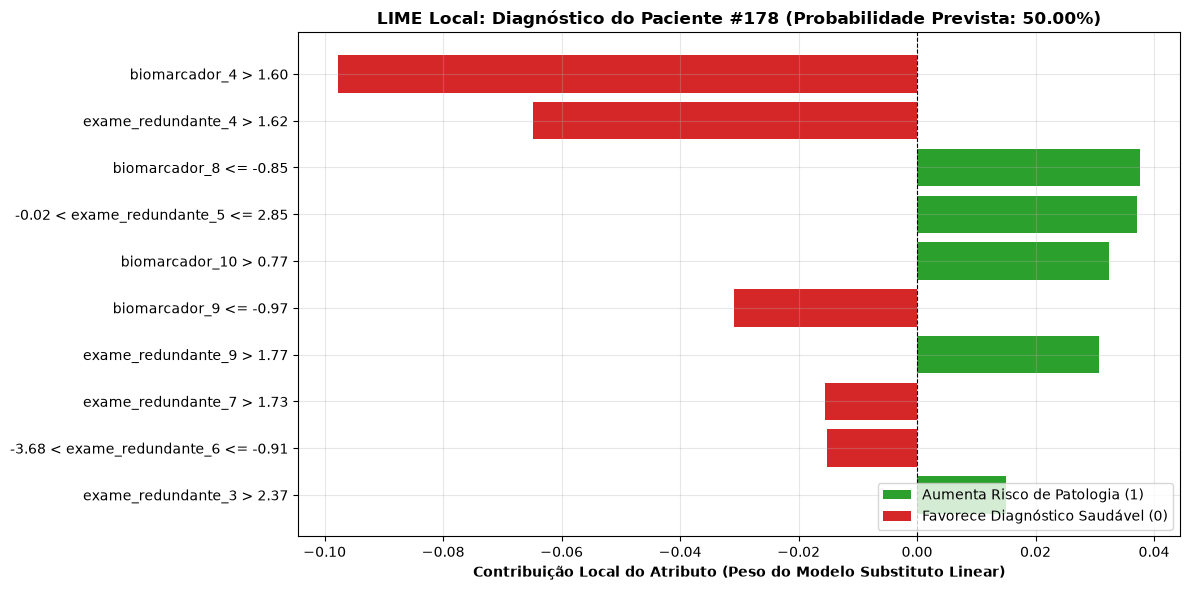

[+] Gráfico explicativo do LIME renderizado e salvo em: modulo3_lime_local.png


In [5]:
# 1. Definimos a funcao para plotar o grafico de barras da explicacao local
def gerar_grafico_lime(df_lime, proba_instancia, index_instancia=0, output_path="modulo3_lime_local.png"):
    """
    Plota os pesos locais calculados pelo LIME para a instância analisada.
    """
    # 2. Instanciamos a figura grafica
    plt.figure(figsize=(12, 6))
    
    # 3. Definimos a paleta semantica: Verde para patologia e Vermelho para saudavel
    cores = ['#2ca02c' if peso > 0 else '#d62728' for peso in df_lime['peso_local']]
    
    # 4. Plotamos as barras horizontais invertidas para colocar o maior fator no topo
    plt.barh(df_lime['regra_atributo'][::-1], df_lime['peso_local'][::-1], color=cores[::-1])
    
    # 5. Inserimos uma linha tracejada vertical no zero para destacar a fronteira neutra
    plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
    
    # 6. Configuramos titulos e rotulos explicativos
    plt.title(f"LIME Local: Diagnóstico do Paciente #{index_instancia} (Probabilidade Prevista: {proba_instancia:.2%})", 
              fontsize=12, fontweight="bold")
    plt.xlabel("Contribuição Local do Atributo (Peso do Modelo Substituto Linear)", fontweight="bold")
    plt.grid(True, alpha=0.3)
    
    # 7. Criamos a legenda explicativa para os profissionais de saude
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2ca02c', label='Aumenta Risco de Patologia (1)'),
        Patch(facecolor='#d62728', label='Favorece Diagnóstico Saudável (0)')
    ]
    plt.legend(handles=legend_elements, loc="lower right")
    
    # 8. Ajustamos o espacamento
    plt.tight_layout()
    
    # 9. Salvamos a figura no disco em alta resolucao
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    
    # 10. Exibimos a figura interativamente na tela do Google Colab
    plt.show()
    print(f"[+] Gráfico explicativo do LIME renderizado e salvo em: {output_path}")

# 11. Chamamos a funcao para visualizar o laudo explicativo do paciente
gerar_grafico_lime(df_lime_paciente, proba_limiar, index_instancia=idx_limiar)

---

### Bloco 3.6 — Teste de Sanidade Automatizado do LIME

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que garante que o LIME funcionou corretamente?**  
> Ele precisa retornar uma tabela não-vazia com pesos matemáticos reais cujo somatório absoluto seja diferente de zero, garantindo que o modelo linear local conseguiu se ajustar aos pontos perturbados.

In [6]:
# 1. Definimos a rotina de teste de sanidade automatizada
def teste_de_sanidade_lime(df_lime):
    """
    Sanity Check do Módulo 3:
    - Valida geração das regras e existência de pesos válidos.
    """
    # 2. Confirmamos que o DataFrame gerado contem regras extraidas
    assert len(df_lime) > 0, "Erro: Explicação LIME veio vazia"
    
    # 3. Confirmamos que os pesos atribuidos nao sao todos numericamente nulos
    assert df_lime["peso_local"].abs().sum() > 0, "Erro: Pesos locais do LIME somam zero"
    
    # 4. Exibimos a mensagem de validacao
    print("\n[OK] SANITY CHECK DO LIME APROVADO: Explicação local gerada com regras consistentes e pesos válidos!")

# 5. Executamos o teste de sanidade
teste_de_sanidade_lime(df_lime_paciente)


[OK] SANITY CHECK DO LIME APROVADO: Explicação local gerada com regras consistentes e pesos válidos!


---

## Módulo 4: Prática Orientada & Experimentação Fácil

### Roteiro de Personalização para o Estudante:
Compare a explicação do paciente duvidoso ($P \approx 50\%$) contra um paciente onde o modelo tinha **quase 100% de certeza**!

1. **Altere o paciente avaliado:** No código abaixo, localize o paciente de maior probabilidade predita ou escolha um índice arbitrário (ex: o paciente com índice `np.argmax(y_proba_teste)`).
2. **Execute a célula:** Observe como a escala dos pesos locais é muito mais agressiva e quase todas as barras ficam verdes!

c:\Users\eduar\projetos\xai_data_reduction\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


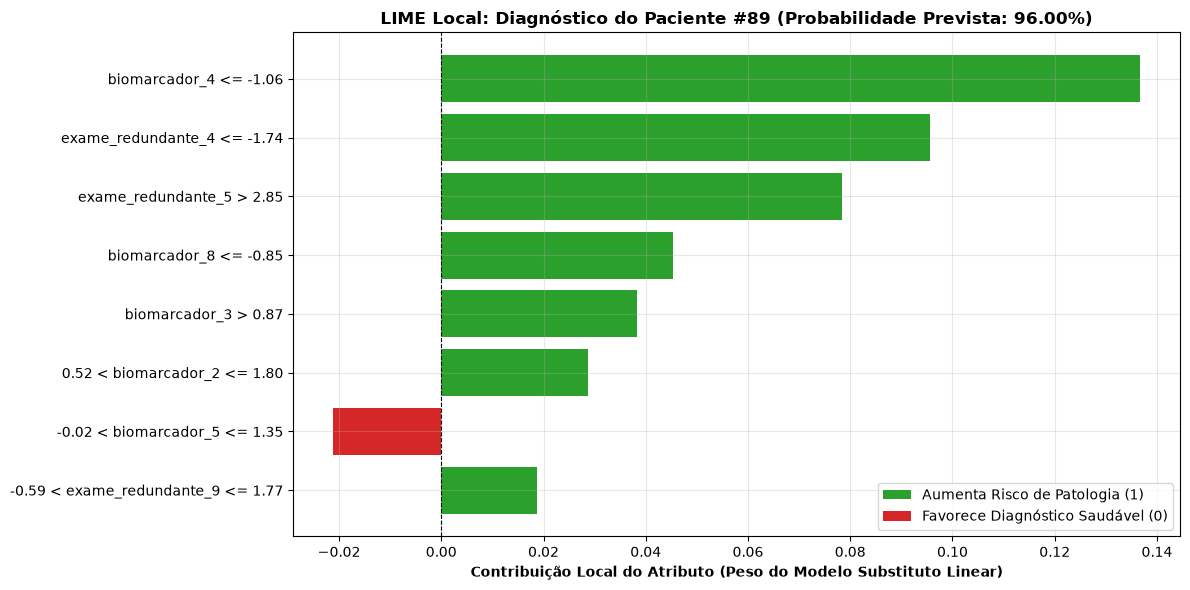

[+] Gráfico explicativo do LIME renderizado e salvo em: modulo3_lime_local.png


In [7]:
# =============================================================================
# CÓDIGO BASE PRONTO PARA SUA EXPERIMENTAÇÃO
# =============================================================================
# -----------------------------------------------------------------------------
# STEP 1: PASSO DE EXPERIMENTAÇÃO DO ALUNO — ESCOLHA O PACIENTE DE TESTE:
# -----------------------------------------------------------------------------
# Localizamos o paciente com maior certeza de doenca (mais proximo de 100%)
idx_paciente_aluno = int(np.argmax(y_proba_teste)) # Tente mudar para 5 ou 10!

# 1. Extraímos a explicacao LIME para o paciente configurado pelo aluno
exp_aluno, df_lime_aluno = explicar_instancia_lime(
    explainer_lime, modelo_baseline, X_test, index_instancia=idx_paciente_aluno, num_features=8
)

# 2. Renderizamos o laudo comparativo
gerar_grafico_lime(df_lime_aluno, y_proba_teste[idx_paciente_aluno], index_instancia=idx_paciente_aluno)

---

### 🔮 Aquecimento & Spoiler da Próxima Aula (Para Ir Além)

> 🧠 **Conceito-Semente — Da Auditoria Passiva à Ação Ativa de Engenharia**  
> Nas Aulas 02 e 03, usamos o XAI como um "espectador curioso": olhamos para a floresta aleatória e vimos quem era importante (SHAP) e como os casos difíceis decidiam (LIME). Mas agora vem o grande momento da ciência de dados:  
> **Se o SHAP já nos provou que 20 atributos são ruídos inúteis e 10 são redundantes, por que continuamos mantendo 40 colunas no modelo?**  
> Na **Aula 04**, realizaremos um **Estudo de Ablação Progressiva**: começaremos com 40 atributos e iremos podando de 2 em 2 até sobrar apenas 2 atributos. Compararemos SHAP com filter (mutual information), wrapper (RFE) e embedded (logística L1), sem transformar a explicação local do LIME em ranking populacional.
> 
> 🚀 **Desafio Proativo de Autoestudo (Opcional):**  
> Pesquise na documentação do scikit-learn como funciona o algoritmo `RFE` (`from sklearn.feature_selection import RFE`) e pense: qual método gasta mais tempo de computador: podar com RFE ou podar com SHAP?

## Módulo 5: Checklist de Autonomia do Estudante

- [ ] Compreendi a importância ética e diagnóstica de auditar instâncias no limiar de decisão ($P \approx 0.50$).
- [ ] Entendi a hipótese da aproximação linear local e a analogia do horizonte plano.
- [ ] Sei instanciar e calibrar o `LimeTabularExplainer` com nomes de colunas e classes.
- [ ] Sei localizar instâncias de máxima incerteza preditiva com `np.argmin(np.abs(proba - 0.5))`.
- [ ] Consigo ler um gráfico do LIME, interpretando o significado das cores (verde vs. vermelho) e das regras condicionais.
- [ ] Executei o teste de sanidade automatizado do LIME com sucesso.

## Referências Bibliográficas & Documentações Oficiais

- 📖 **Artigo Seminal LIME:** Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*. ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD 2016).
- 📖 **Livro Texto:** Molnar, C. (2022). *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable* (Capítulo 5.7: LIME).
- 🔗 **Repositório Oficial do LIME:** [github.com/marcotcr/lime](https://github.com/marcotcr/lime)